In [32]:
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import END, StateGraph
from typing_extensions import TypedDict

In [33]:
class State(TypedDict):
  messages: list
  action_approved: bool

In [34]:
def model_node(state: State):
  # The model decides it needs to run a dangerous tool
  return {"messages": state["messages"] + ["Calling dangerous API..."]}

In [35]:
def tools_node(state: State):
  # This is the sensitive node we want to protect
  return {"messages": state["messages"] + ["API executed successfully!"]}

In [36]:
workflow = StateGraph(State)
workflow.add_node("model", model_node)
workflow.add_node("tools", tools_node)

workflow.set_entry_point("model")
workflow.add_edge("model","tools")
workflow.add_edge("tools", END)

# 1. Initialize checkpointer (REQUIRED for interrupts)
checkpointer = MemorySaver()

# 2. Compile with interrupt_before targeting the sensitive node
app = workflow.compile(
    checkpointer=checkpointer, interrupt_before=["tools"]  # <--- The magic happens here
)

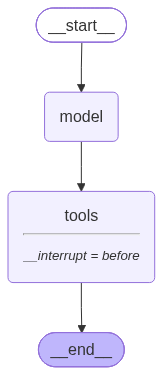

In [37]:
app

In [38]:
config = {"configurable": {"thread_id": "hitl_session_1"}}

# This will run 'model', then pause right before entering 'tools'
app.invoke({"messages": ["Delete user database"], "action_approved": False}, config=config)

{'messages': ['Delete user database', 'Calling dangerous API...'],
 'action_approved': False}

In [39]:
state_snapshot = app.get_state(config)
print("Next nodes to execute:", state_snapshot.next)
# Output will show: ('tools',) -> meaning it's waiting right at the tools node!

Next nodes to execute: ('tools',)


In [40]:
# Resumes execution from the exact checkpoint
final_result = app.invoke(None, config=config)
print("Final Result after resume:", final_result)

Final Result after resume: {'messages': ['Delete user database', 'Calling dangerous API...', 'API executed successfully!'], 'action_approved': False}


In [41]:
config = {"configurable": {"thread_id": "hitl_session_2"}}

for event in app.stream({"messages": ["Delete user database"], "action_approved": False},config = config ,stream_mode="updates"):
  print(event)
  print("-" * 40)

{'model': {'messages': ['Delete user database', 'Calling dangerous API...']}}
----------------------------------------
{'__interrupt__': ()}
----------------------------------------


In [42]:
config = {"configurable": {"thread_id": "hitl_session_2"}}

for event in app.stream({"messages": ["Delete user database"], "action_approved": False},config = config ,stream_mode="values"):
  print(event)
  print("-" * 40)

{'messages': ['Delete user database'], 'action_approved': False}
----------------------------------------
{'messages': ['Delete user database', 'Calling dangerous API...'], 'action_approved': False}
----------------------------------------


How can we update action_approved from False to True in the saved state without restarting the workflow?

Calling app.invoke() with a new input is not the correct way to update an interrupted workflow. It can start a new execution on that thread.

app.update_state(
    config,
    {"action_approved": True}
)

app.invoke(None, config=config)

Here, update_state() modifies the saved state, and invoke(None) resumes execution from the checkpoint.